# Module 1 — Why RAG Exists

Part of the RAG Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

**What a language model is**
- A language model is the kind of program behind chat assistants such as ChatGPT. You type a question, and it writes an answer.
- It is built by training: it reads a huge amount of text, such as websites and books, and learns how words, facts and ideas usually go together.
- To answer, it writes new text by combining what it learned, so it can write answers nobody wrote before.
- But it cannot know a fact that was not in its training text. Two kinds of facts are always missing:
  1. anything that happened after its training text was collected. That date is called the training cutoff.
  2. anything private, such as a company's own reports, contracts or support tickets
- Asked about a fact it never read, the model either says it doesn't know or makes up an answer that sounds right.

**How to give the model new facts**
- Everything you give the model together with your question is called the prompt. The model reads the prompt at the moment you ask, and can use what is in it.
- So a model can answer from a document it never read in training, if that document is pasted into the prompt.
- After answering, the model forgets the prompt. Every question starts from nothing again.
- The documents you want answers from are called the collection, for example all of a company's support tickets.
- There are three ways to make the model answer from a collection:
  1. Retrain the model on the collection, so the collection's facts end up inside the model. This is called fine-tuning. It needs a powerful graphics card, and it has to be redone whenever the collection changes. The laptop this playbook was built on has no such card, so this module explains retraining but doesn't run it.
  2. Paste the whole collection into the prompt, with every question. This is the simplest way, and it works when the collection is small. But a model can read only a limited amount of text at once, so a large collection doesn't fit.
  3. Search the collection first, and paste in only the few documents that match the question. This is RAG, short for retrieval-augmented generation. "Retrieval" is the search. "Augmented generation" means the model writes (generates) its answer with those documents added to the prompt.

**How RAG works**
- RAG uses two separate programs:
  1. A search program. You give it the collection once, and it stores it, the way a database stores a table. For each question, it compares the question with every stored document and returns the few that match best, like the search box on a website. It writes no answer.
  2. The language model. It gets the question plus the documents the search returned, reads those documents for the first time, and writes the answer from them.
- The search still looks at every document for each question, but that is fast: when it stores the collection, it turns each document once into a short list of numbers, and for each question it only compares numbers, which takes a fraction of a second. The model reading a document is slow: it works through the text word by word. So the search does the cheap work on the whole collection, and the model does the slow work on a few documents only.
- So the model never needs to have learned the collection. It only needs the right documents in its prompt.
- A chat assistant that searches the web before it answers works the same way, with the web as its collection.
- RAG can fail in two places:
  1. The search returns the wrong documents, so the model answers without the facts it needs.
  2. The model gets the right documents but answers wrongly from them.
- This playbook builds the search program, uses a ready-made language model, and measures both.

**What this module tests**

The collection is 609 news articles from late 2023, from a public dataset called MultiHop-RAG, which was built to test RAG. The dataset also has questions about those articles. For each question, it gives the correct answer and lists which articles hold that answer. This module uses 30 of those questions. The model is a small language model running on the laptop this playbook was built on.

The same 30 questions are run in three setups.

1. The model alone. The prompt holds only the question, with no articles. How many questions does it answer right? It runs twice: once allowed to say "I don't know", and once told to always answer, to see what the model says when it has to guess. This is the score before any help. It may not be zero: the model's training cutoff is December 2023, so it may have read about some of these events.
2. The articles that hold each answer are taken from the dataset's list and pasted into the prompt. No search is used. How many does it answer right now? It runs once, allowed to say "I don't know". This is the best score a perfect search could reach. If the model fails here, no search can fix it.
3. All 609 articles are pasted into the prompt. Do they fit, and how long would the model take to read them?

**Two tags in this module**
- **[in real life]** marks a step an analyst can run on real work.
- **[only in this module]** marks a step that uses the dataset's list of which articles hold each answer. In real life, when a user asks a new question, nobody has that list. Finding those articles is the search program's job.
- Grading the model's answers against known correct answers is real-life work. Analysts write test questions with known answers to check a RAG system.

**What this module produces**
1. The model's score on the 30 questions with no articles, run twice: once allowed to say "I don't know", once told to always answer.
2. The model's score on the same 30 questions with the right articles added, run once: allowed to say "I don't know".
3. A measurement of why the whole collection can't be added to a question.
4. A comparison table with 4 columns: setup 1 (the model alone), and the 3 ways to give the model new facts (retrain, paste the whole collection, and RAG).

## From the curriculum

> ## <u>Module 1 — Why RAG Exists</u>
>
> **Concepts**
> - What a language model knows: only the facts that were in its training text,
>   up to a cutoff date
> - Three ways to give it new facts: retrain it, paste the whole collection into
>   the prompt, or search the collection and paste in only the matching documents
>   (RAG, retrieval-augmented generation)
> - The context window: the most text a model can read at once
> - The five parts a RAG system is built from, each built in a later module
>
> **Worked example:** the same questions answered with no articles, with the
> right articles pasted in, and with the whole collection, which does not fit.
> Retraining is explained, not run: it needs a graphics card.

## Lesson

### Tokens: the pieces a model reads and writes

- A model does not read whole words. It reads **tokens**: pieces of words. A common word is one token. A rare word or a name is split into several tokens.
- To answer, the model writes one token at a time. Each time, it picks a likely next piece, given everything written before it.
- Every limit and every speed in this module is counted in tokens.

### The model in this module

Llama 3.2, made by Meta, in its small size: about 3 billion internal numbers. Training adjusts these numbers, and they are where the model stores what it learned. Its training cutoff is December 2023, according to [Meta's description of the model](https://huggingface.co/meta-llama/Llama-3.2-3B-Instruct).

### The context window: how much text the model reads at once

- A model can read only a limited number of tokens at once. That limit is called the **context window**. It covers the prompt plus the answer the model writes.
- Text that does not fit in the window is not read at all.
- Every model has a **largest window** it was built for. Llama's largest window is 131,072 tokens. This limit is fixed: it comes from how Llama was built.
- Ollama, the free program that runs Llama on this laptop, sets aside memory for a window before each run. Unless asked for more, Ollama gives Llama a window of only 4,096 tokens, because a larger window needs more memory. 4,096 is an Ollama setting, not a limit of Llama. It is enough for a short prompt. For a long prompt, this module's code asks Ollama for a larger window, big enough to hold the prompt.

## The data: news articles and questions with known answers

The dataset is MultiHop-RAG (Tang and Yang, 2024). "Multi-hop" means that answering a question needs facts from more than one article. It has two parts:
- 609 news articles, published between September and December 2023
- 2,556 questions about those articles. For each question, the dataset gives the correct answer, and the sentences in the articles that support it. The articles those sentences come from are the articles that hold the answer.

The questions come in four types:

| Type | What it asks | Answer |
|---|---|---|
| comparison | compares what two articles say | mostly yes or no |
| temporal | asks about the order of events in time | mostly yes or no |
| null | asks something no article answers | "Insufficient information." |
| inference | asks who or what fits facts spread over two to four articles | a person, company, team or organisation, or a group such as "Bettors" |

This module uses only the inference questions, because their answers are names. A yes/no question would not work here: a model that always guesses "yes" is right on many of them by chance. A null question would not work either: its answer is always the same phrase.

The code below loads the data with `common`, this playbook's shared helper file. It loads the data, calls the language model, and prints tables.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common
from common import show, GRADE_COLORS

articles = common.load_corpus()
questions = common.load_questions()
inference = questions[questions["question_type"] == "inference_query"].copy()
print(f"Articles = {len(articles)}")
print(f"Questions = {len(questions)}")
print(f"Inference questions = {len(inference)}")

Articles = 609
Questions = 2556
Inference questions = 816


One inference question, its correct answer, and the supporting sentences the dataset lists for it. The articles these sentences come from are the ones Setup 2 (the right articles added) pastes into the prompt:

In [2]:
example = inference.iloc[0]
print("Question:", example["query"])
print()
print("Correct answer:", example["answer"])
print()
for n, ev in enumerate(example["evidence_list"], 1):
    print(f"Supporting sentence {n} of {len(example['evidence_list'])}, from {ev['source']}, {ev['published_at'][:10]}:")
    print("  ", ev["fact"])

Question: Who is the individual associated with the cryptocurrency industry facing a criminal trial on fraud and conspiracy charges, as reported by both The Verge and TechCrunch, and is accused by prosecutors of committing fraud for personal gain?

Correct answer: Sam Bankman-Fried

Supporting sentence 1 of 3, from The Verge, 2023-09-28:
   Before his fall, Bankman-Fried made himself out to be the Good Boy of crypto — the trustworthy face of a sometimes-shady industry.
Supporting sentence 2 of 3, from TechCrunch, 2023-10-01:
   The highly anticipated criminal trial for Sam Bankman-Fried, former CEO of bankrupt crypto exchange FTX, started Tuesday to determine whether he’s guilty of seven counts of fraud and conspiracy.
Supporting sentence 3 of 3, from TechCrunch, 2023-10-07:
   The prosecution painted Bankman-Fried as someone who knowingly committed fraud to achieve great wealth, power and influence, while the defense countered that the FTX founder acted in good faith, never meant to c

### Choosing 30 questions

The model runs on the laptop's processor, so reading one question with its articles is slow. 30 questions keep the run time manageable, and are enough to show differences of many questions between the setups. 30 is still a small test: the exact shares would differ on another 30, so read every share in this module as rough.

Some correct answers repeat across many questions: one person is the answer to hundreds of them. A random draw of 30 could then be mostly about one story, and a model that happens to know that story would look good on much of the test. So the 30 questions are drawn with 30 different correct answers, in three steps. As a result, each score shows how the model does on 30 different answers. It is not an estimate of its score on all 816 inference questions.

**Step 1 of 3: one spelling per answer.** The dataset writes some answers in more than one way, such as "Google" and "Google.", which would count as two different answers. So every answer loses a final full stop, a leading "The" and any words in brackets, and one name is merged by hand.

In [3]:
SAME_NAME = {"New Zealand All Blacks": "All Blacks"}


def one_spelling(answer: str) -> str:
    a = answer.strip().rstrip(".")
    a = a.split(" (")[0]
    a = a[4:] if a.startswith("The ") else a
    return SAME_NAME.get(a, a)


inference["answer, one spelling"] = inference["answer"].map(one_spelling)
merged = inference.loc[inference["answer"] != inference["answer, one spelling"], ["answer", "answer, one spelling"]]
print("Answers whose spelling changed:")
print()
show(merged.drop_duplicates().sort_values("answer, one spelling"))
print()
print(f"Different correct answers = {inference['answer'].nunique()} as written, {inference['answer, one spelling'].nunique()} with one spelling each")

Answers whose spelling changed:

answer                                            answer, one spelling
The All Blacks (New Zealand national rugby team)  All Blacks
New Zealand All Blacks                            All Blacks
Companies.                                        Companies
Consumers.                                        Consumers
The European Commission.                          European Commission
The European Commission                           European Commission
The Federal Reserve                               Federal Reserve
Google.                                           Google
Sam Altman.                                       Sam Altman
Sam Bankman-Fried.                                Sam Bankman-Fried
Sportsbooks.                                      Sportsbooks

Different correct answers = 72 as written, 63 with one spelling each


11 spellings changed, and the count of answers fell by 9. 9 of the changed spellings became a spelling the dataset already uses for other questions, such as "Google." becoming "Google". The other 2, "Companies." and "Consumers.", only lost their full stop, and had no other spelling to merge with.

**Step 2 of 3: how many of a plain random 30 would share one answer.**

In [4]:
top = inference["answer, one spelling"].value_counts().head(3)
print("Most common correct answers among the inference questions:")
print()
show(pd.DataFrame({"correct answer": top.index, "questions": top.values,
                   "share of the inference questions": [f"{v / len(inference):.0%}" for v in top.values]}))
print()
sbf = top.iloc[0]
print("Sam Bankman-Fried questions expected in a random draw of 30 = 30 × (Sam Bankman-Fried questions / inference questions)")
print(f"  = 30 × ({sbf} / {len(inference)})")
print(f"  = {30 * sbf / len(inference):.1f}")

Most common correct answers among the inference questions:

correct answer     questions  share of the inference questions
Sam Bankman-Fried        275                               34%
Google                   212                               26%
Sam Altman                58                                7%

Sam Bankman-Fried questions expected in a random draw of 30 = 30 × (Sam Bankman-Fried questions / inference questions)
  = 30 × (275 / 816)
  = 10.1


**Observation:** one correct answer, Sam Bankman-Fried, covers about a third of the inference questions, so a random draw of 30 would hold about 10 questions about him.

**Step 3 of 3: the draw.** 30 of the 63 different correct answers are chosen at random, then one random question for each. The seed, a fixed starting number for the random draw, makes the same 30 questions come back on every run.

In [5]:
rng = np.random.default_rng(common.SEED)
chosen_answers = rng.choice(sorted(inference["answer, one spelling"].unique()), size=30, replace=False)
sample = pd.concat([inference[inference["answer, one spelling"] == a].sample(1, random_state=common.SEED)
                    for a in chosen_answers]).reset_index(drop=True)
assert len(sample) == 30 and sample["answer, one spelling"].nunique() == 30

### How an answer is graded

To count how many questions each setup gets right, every answer gets one of three grades:

| Grade | Rule |
|---|---|
| right | the correct answer, in its one spelling, appears in the model's answer, ignoring capital letters |
| did not answer | the model's answer holds one of the phrases printed below, such as "don't know", "cannot" or "unable to" |
| wrong | anything else: the model named an answer, and it is not the correct one |

The checks run in the table's order: "right" first, then "did not answer". So an answer that holds both the correct name and a phrase such as "not sure" counts as right.

"Did not answer" covers both "I don't know" and refusals such as "I cannot provide information on…": in both, the model gives no name.

This automatic rule can misjudge. "SBF" is a right answer for "Sam Bankman-Fried", but the rule would call it wrong. So every grade in the three runs below, two in Setup 1 and one in Setup 2, is read by hand, the right ones included. The code prints each grade the hand check changed, with its question and its reason. It also prints each close call it kept: an answer near the correct one, such as "Large enterprises" for "Companies", whose grade stayed the same. The score counts the grade after the hand check.

Every answer is capped at 60 tokens. The instruction given with every question asks for a few words, so the cap only cuts long, wandering answers. The grade is given on whatever was written.

The tables show each correct answer in its one spelling. Long answers are cut at 70 characters in the tables, marked "…". The grade is always given on the full answer.

In [6]:
NO_ANSWER = ["don't know", "do not know", "not aware", "no information", "unable to", "cannot", "can't",
             "couldn't find", "could not find", "not sure", "i'm sorry"]
print("Phrases that mean 'did not answer':")
print("  " + ", ".join(f'"{p}"' for p in NO_ANSWER))

Phrases that mean 'did not answer':
  "don't know", "do not know", "not aware", "no information", "unable to", "cannot", "can't", "couldn't find", "could not find", "not sure", "i'm sorry"


In [7]:
def grade(answer: str, correct: str) -> str:
    a = answer.lower()
    if one_spelling(correct).lower() in a:
        return "right"
    if any(p in a for p in NO_ANSWER):
        return "did not answer"
    return "wrong"


# Grades the hand check changed: (test, correct answer) -> (grade after the hand check, reason)
HAND_CHECK = {
    ("may say", "Sportsbooks"): ("right", "the question asks for 'the common term', and bookmakers are the same businesses as sportsbooks"),
    ("must answer", "Sportsbooks"): ("right", "the question asks for 'the common term', and bookmakers are the same businesses as sportsbooks"),
    ("must answer", "Australia's cricket team"): ("right", "the question asks for a national team, and national teams are named by their country"),
    ("articles added", "Australia's cricket team"): ("right", "the question asks for a national team, and national teams are named by their country"),
    ("articles added", "Everton Football Club"): ("right", "'Everton' is the club's short name"),
    ("must answer", "Companies."): ("wrong", "'Large enterprises' names a narrower group than companies in general"),
    ("articles added", "Companies."): ("wrong", "the answer names three companies, while the question asks for the group, companies in general"),
    ("articles added", "Bettors"): ("wrong", "sports fans do not all bet"),
}


def grade_all(test: str, answers: pd.Series) -> list:
    graded, changed = [], 0
    for answer, correct, question in zip(answers, sample["answer"], sample["query"]):
        auto = grade(answer, correct)
        final, reason = HAND_CHECK.get((test, correct), (auto, ""))
        if reason:
            changed += final != auto
            what = f"{auto} -> {final}" if final != auto else f"kept as {final}"
            print(f"Hand check, '{one_spelling(correct)}': {what}, because {reason}.")
            print(f"  Question: {question}")
            print()
        graded.append(final)
    print(f"Grades changed by the hand check = {changed} of {len(answers)}")
    return graded


def score(grades: pd.Series) -> pd.DataFrame:
    order = ["right", "did not answer", "wrong"]
    counts = grades.value_counts().reindex(order, fill_value=0)
    return pd.DataFrame({"grade": order, "questions": counts.values,
                         "share": [f"{c / len(grades):.0%}" for c in counts.values]})


def short(text: str) -> str:
    text = " ".join(text.split())
    return text if len(text) <= 70 else text[:69] + "…"


def answers_table(column: str) -> None:
    show(pd.DataFrame({"#": range(1, len(sample) + 1), "correct answer": sample["answer, one spelling"], "model's answer": sample[column + ": answer"].map(short),
                       "grade": sample[column + ": grade"]}))


ALLOW_DONT_KNOW = "Answer in a few words. If you do not know, say 'I don't know'."
ALWAYS_ANSWER = "Answer in a few words."

## Setup 1: the model alone

### First run: allowed to say "I don't know"

**[in real life]** The model gets only the question and an instruction: "Answer in a few words. If you do not know, say 'I don't know'." Nothing about the news is added.

In [8]:
alone_runs = [common.generate(f"Question: {q}\n{ALLOW_DONT_KNOW}", max_tokens=60, full=True) for q in sample["query"]]
sample["alone: answer"] = [r["answer"] for r in alone_runs]
sample["alone: grade"] = grade_all("may say", sample["alone: answer"])
print()
answers_table("alone")

Hand check, 'Sportsbooks': wrong -> right, because the question asks for 'the common term', and bookmakers are the same businesses as sportsbooks.
  Question: What is the common term for the entities that may change their betting lines based on news or sentiment about a team's chances, can refund bets for weather-suspended games depending on their rules, profit from odds and lines regardless of the outcomes, and adjust NBA Rookie of the Year betting lines according to the information they gather, as reported by Sporting News?

Grades changed by the hand check = 1 of 30

 #  correct answer                     model's answer   grade
 1  Tyreek Hill                        I don't know.    did not answer
 2  Richelle Cranston                  I don't know.    did not answer
 3  Lionel Messi                       I don't know.    did not answer
 4  India                              I don't know.    did not answer
 5  Apple                              I don't know.    did not answer
 6  Au

In [9]:
print("Setup 1, the model alone, allowed to say 'I don't know' (30 questions):")
print()
show(score(sample["alone: grade"]))

Setup 1, the model alone, allowed to say 'I don't know' (30 questions):

grade           questions  share
right                   3    10%
did not answer         27    90%
wrong                   0     0%


**Observation:** the model did not answer 27 of the 30 questions, and named an answer for only 3.

That does not show the model knows none of the answers. The instruction offered "I don't know" as a way out, and the model may have taken it even when it could have answered. To see what the model can answer from its training, the second run removes the way out.

### Second run: told to always answer

**[in real life]** The same 30 questions, with the instruction cut to "Answer in a few words."

In [10]:
must_runs = [common.generate(f"Question: {q}\n{ALWAYS_ANSWER}", max_tokens=60, full=True) for q in sample["query"]]
sample["must: answer"] = [r["answer"] for r in must_runs]
sample["must: grade"] = grade_all("must answer", sample["must: answer"])
print()
answers_table("must")

Hand check, 'Australia's cricket team': wrong -> right, because the question asks for a national team, and national teams are named by their country.
  Question: What team, which has players like Steve Smith and Aaron Finch contributing to a score of 328 for 7 wickets in a 2015 World Cup semi-final and also won a match against India by just one run, recently experienced their first four-day game loss since January 2014 during a tour of India, as reported by 'The Roar | Sports Writers Blog' and 'Zee Business'?

Hand check, 'Sportsbooks': wrong -> right, because the question asks for 'the common term', and bookmakers are the same businesses as sportsbooks.
  Question: What is the common term for the entities that may change their betting lines based on news or sentiment about a team's chances, can refund bets for weather-suspended games depending on their rules, profit from odds and lines regardless of the outcomes, and adjust NBA Rookie of the Year betting lines according to the informa

In [11]:
print("Setup 1, the model alone, told to always answer (the same 30 questions):")
print()
show(score(sample["must: grade"]))

Setup 1, the model alone, told to always answer (the same 30 questions):

grade           questions  share
right                  11    37%
did not answer         12    40%
wrong                   7    23%


**Observation:** told to always answer, the model got 11 questions right, still did not answer 12, and gave 7 wrong answers. Most wrong answers name a real company or team ("TikTok" for Twitch and for YouTube, "FanDuel" for Caesars Sportsbook), stated as plainly as the right ones.

4 of the 12 "did not answer" grades are refusals, worded "I cannot provide information…": the model declines to discuss the topic, rather than saying it lacks the facts, as "I cannot verify…" does. Models like this one are trained to decline some topics. So the 4 refusals count as "did not answer", but they say nothing about whether the model knows the answer.

**Hypothesis:** the right answers come from two sources together: clues in the questions themselves, and what the model read before its cutoff. For example, the question whose answer is Australia's cricket team, printed in the hand check above, names the players Steve Smith and Aaron Finch. This module does not test the hypothesis: it needs questions with no clues to the answer.

**Conclusion:** with no articles, the model cannot be trusted on this news. Allowed to say "I don't know", it says so to almost everything. Told to answer, it gives wrong answers in the same plain tone as right ones, so the person reading the answers cannot tell the two apart.

## Setup 2: the right articles added

**[only in this module]** For each question, the prompt holds the articles that hold its answer, taken from the dataset's list, then the question and the same instruction as Setup 1's first run, which allows "I don't know". So two things differ from Setup 1's first run:
1. the added articles
2. the context window, made large enough to hold them

**How large:** the window is set to 2 tokens per word of the prompt (the articles, the question and the instruction, plus 20 words to spare), rounded up to the next 1,000. 2 is a deliberately high guess: a common word is one token, and only rare words and names split into several. A window too small would make Ollama silently drop the start of the prompt, so the code stops with an error if a prompt fills its window.

Of these two differences, the window cannot change an answer: it only limits how much the model can read. So any change in the answers comes from the articles.

In [12]:
by_url = articles.set_index("url")


def articles_text(evidence: list) -> str:
    urls = list(dict.fromkeys(ev["url"] for ev in evidence))
    return "\n\n".join(f"Article: {by_url.at[u, 'title']}\n{by_url.at[u, 'body']}" for u in urls)


def window_for(text: str, question: str) -> int:
    words = len(text.split()) + len(question.split()) + 20
    return int(np.ceil(words * 2 / 1000) * 1000)


runs = []
for q, ev in zip(sample["query"], sample["evidence_list"]):
    text = articles_text(ev)
    runs.append(common.generate(f"{text}\n\nQuestion: {q}\n{ALLOW_DONT_KNOW}",
                                max_tokens=60, num_ctx=window_for(text, q), full=True))
sample["added: answer"] = [r["answer"] for r in runs]
sample["added: grade"] = grade_all("articles added", sample["added: answer"])
sample["article words"] = [len(articles_text(ev).split()) for ev in sample["evidence_list"]]
sample["prompt tokens"] = [r["prompt_tokens"] for r in runs]
sample["question tokens"] = [r["prompt_tokens"] for r in alone_runs]
sample["reading seconds"] = [r["prompt_seconds"] for r in runs]
print()
answers_table("added")

Hand check, 'Australia's cricket team': wrong -> right, because the question asks for a national team, and national teams are named by their country.
  Question: What team, which has players like Steve Smith and Aaron Finch contributing to a score of 328 for 7 wickets in a 2015 World Cup semi-final and also won a match against India by just one run, recently experienced their first four-day game loss since January 2014 during a tour of India, as reported by 'The Roar | Sports Writers Blog' and 'Zee Business'?

Hand check, 'Bettors': kept as wrong, because sports fans do not all bet.
  Question: Which group of individuals can take advantage of hype around specific events to make money by placing wagers on scenarios such as whether a team will lead at the end of a certain quarter, as reported by Sporting News?

Hand check, 'Everton Football Club': wrong -> right, because 'Everton' is the club's short name.
  Question: What football club would have been in an improved league position with

In [13]:
print("Setup 2, the right articles added (the same 30 questions):")
print()
show(score(sample["added: grade"]))

Setup 2, the right articles added (the same 30 questions):

grade           questions  share
right                  26    87%
did not answer          0     0%
wrong                   4    13%


### The setups side by side

The three score tables above, in one chart. Setup 3 is not in it: it measures size and time, not answers. In the chart's labels, "may say 'I don't know'" is the first run, allowed to say "I don't know", and "must answer" is the second run, told to always answer.

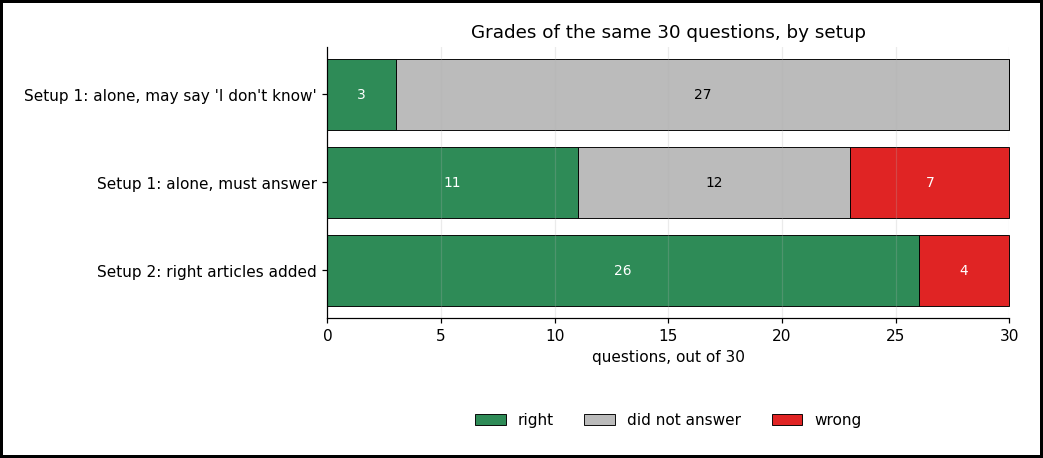

In [14]:
both = pd.DataFrame({"Setup 1: alone, may say 'I don't know'": score(sample["alone: grade"]).set_index("grade")["questions"],
                     "Setup 1: alone, must answer": score(sample["must: grade"]).set_index("grade")["questions"],
                     "Setup 2: right articles added": score(sample["added: grade"]).set_index("grade")["questions"]}).T
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(both))
for grade_name in both.columns:
    color, text_color = GRADE_COLORS[grade_name]
    ax.barh(both.index, both[grade_name], left=left, color=color, edgecolor="black", linewidth=0.6, clip_on=False, label=grade_name)
    for y, (l, v) in enumerate(zip(left, both[grade_name])):
        if v:
            ax.text(l + v / 2, y, str(v), ha="center", va="center", color=text_color, fontsize=9)
    left += both[grade_name].values
ax.invert_yaxis()
ax.set_xlim(0, 30)
ax.set_xlabel("questions, out of 30")
ax.set_title("Grades of the same 30 questions, by setup")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
ax.grid(axis="y", visible=False)
plt.show()

In the chart, Setup 2's bar is almost all "right", while Setup 1's first run is almost all "did not answer".

Setup 1's first run and Setup 2 use the same instruction, and Setup 2 adds the articles. Counting how each question's grade moved between the two shows, question by question, whether the articles are what turned grades to right:

In [15]:
order = ["right", "did not answer", "wrong"]
moves = pd.crosstab(sample["alone: grade"].rename("Setup 1, first run"), sample["added: grade"])
moves = moves.reindex(index=order, columns=order, fill_value=0)
moves.columns = [f"[SU2] {c}" for c in moves.columns]
moves.index = [f"[SU1, 1st run] {g}" for g in moves.index]
moves.index.name = ""
print("Questions, by grade in Setup 1's first run (rows) and in Setup 2 (columns):")
print()
show(moves, index=True)
print()
print("SU = Setup")

Questions, by grade in Setup 1's first run (rows) and in Setup 2 (columns):

                               [SU2] right  [SU2] did not answer  [SU2] wrong
[SU1, 1st run] right                     1                     0            2
[SU1, 1st run] did not answer           25                     0            2
[SU1, 1st run] wrong                     0                     0            0

SU = Setup


**Observation:** of the 27 questions the model did not answer in Setup 1's first run, 25 turned right with the articles added, and 2 turned wrong. Of the 3 it answered right with no articles, 1 stayed right and 2 turned wrong ("Binance" for FTX, "Sports fans" for Bettors). So with the articles added, 2 + 2 = 4 questions got wrong answers. This module does not trace why the articles led to these 4. The 2 right answers that turned wrong may mean that adding articles can also mislead the model, but 2 questions are too few to tell.

Setup 2 has no second run told to always answer, unlike Setup 1: with the articles added, the model already answered all 30 questions, so there was nothing left to force.

For 8 of those 25 questions, Setup 1's second run shows the model could name the right answer with no articles when told to always answer: Tyreek Hill, Lionel Messi, India, Apple, Australia's cricket team, Will Smith and Jada Pinkett Smith, Taylor Swift and European Commission. For those 8, the articles may have given the model the confidence to answer more than the facts.

**Conclusion:** under the same instruction, adding the right articles turned most unanswered questions into right answers.

## Setup 3: the whole collection added

**[in real life]** Setup 2 used the dataset's list of which articles hold each answer. Without that list, the simplest way is to paste the whole collection, all 609 articles, into every prompt.

Two measurements show whether that can work: does the collection fit in the largest window, and how long would the model take to read it.

**Step 1 of 3: tokens per word.** The window is counted in tokens, but the model reports tokens only for prompts it actually read. The whole collection was never given to the model, so its tokens are estimated from its words, using the tokens per word of the Setup 2 articles. Any articles would do for this: tokens per word measures the text, and does not depend on the dataset's list.

A Setup 2 prompt is the articles plus the question and instruction, and Setup 1's first-run prompt is the same question and instruction alone. So the difference between the two is the articles' tokens.

In [16]:
article_tokens = sample["prompt tokens"].sum() - sample["question tokens"].sum()
print("Article tokens = (tokens in the 30 Setup 2 prompts) − (tokens in the 30 Setup 1 first-run prompts)")
print(f"  = {sample['prompt tokens'].sum():,} − {sample['question tokens'].sum():,}")
print(f"  = {article_tokens:,}")

Article tokens = (tokens in the 30 Setup 2 prompts) − (tokens in the 30 Setup 1 first-run prompts)
  = 181,905 − 3,220
  = 178,685


In [17]:
tokens_per_word = round(article_tokens / sample["article words"].sum(), 4)
print("Tokens per word = (article tokens) / (words in the articles)")
print(f"  = {article_tokens:,} / {sample['article words'].sum():,}")
print(f"  = {tokens_per_word:.4f}")

Tokens per word = (article tokens) / (words in the articles)
  = 178,685 / 139,678
  = 1.2793


**Step 2 of 3: the collection against the largest window.**

In [18]:
collection_words = ("Article: " + articles["title"] + " " + articles["body"]).str.split().str.len().sum()
collection_tokens = round(collection_words * tokens_per_word)
window = common.context_length()
print("Collection tokens = (words in all 609 articles, with their titles, as Setup 2 added them) × (tokens per word)")
print(f"  = {collection_words:,} × {tokens_per_word:.4f}")
print(f"  = {collection_tokens:,}")
print()
print(f"Largest window the model was built for, as Ollama reports it = {window:,} tokens")
print()
print("Times the largest window fits in the collection = (collection tokens) / (largest window)")
print(f"  = {collection_tokens:,} / {window:,}")
print(f"  = {collection_tokens / window:.1f}")

Collection tokens = (words in all 609 articles, with their titles, as Setup 2 added them) × (tokens per word)
  = 1,071,839 × 1.2793
  = 1,371,204

Largest window the model was built for, as Ollama reports it = 131,072 tokens

Times the largest window fits in the collection = (collection tokens) / (largest window)
  = 1,371,204 / 131,072
  = 10.5


**Step 3 of 3: the reading time, if the collection did fit.**

In [19]:
speed = round(sample["prompt tokens"].sum() / sample["reading seconds"].sum(), 1)
print("Reading speed = (tokens in the 30 Setup 2 prompts) / (seconds the model spent reading them)")
print(f"  = {sample['prompt tokens'].sum():,} / {sample['reading seconds'].sum():,.0f}")
print(f"  = {speed:.1f} tokens per second")
print()
hours = collection_tokens / speed / 3600
print("Hours to read the collection, for every question")
print("  = (collection tokens / reading speed) / (3,600 seconds in an hour)")
print(f"  = ({collection_tokens:,} / {speed:.1f}) / 3,600")
print(f"  = {hours:.1f}")

Reading speed = (tokens in the 30 Setup 2 prompts) / (seconds the model spent reading them)
  = 181,905 / 4,012
  = 45.3 tokens per second

Hours to read the collection, for every question
  = (collection tokens / reading speed) / (3,600 seconds in an hour)
  = (1,371,204 / 45.3) / 3,600
  = 8.4


**Is the speed the same for longer prompts?** The hours above assume it is. Setup 2's 30 prompts range from about two thousand tokens to about eleven thousand, so comparing their shorter half with their longer half tests that:

In [20]:
by_size = sample.sort_values("prompt tokens")
for name, half in [("Shorter 15 prompts", by_size.iloc[:15]), ("Longer 15 prompts", by_size.iloc[15:])]:
    print(f"{name}, {half['prompt tokens'].min():,} to {half['prompt tokens'].max():,} tokens:")
    print("  Reading speed = (their tokens) / (their reading seconds)")
    print(f"  = {half['prompt tokens'].sum():,} / {half['reading seconds'].sum():,.0f}")
    print(f"  = {half['prompt tokens'].sum() / half['reading seconds'].sum():.1f} tokens per second")
    print()

Shorter 15 prompts, 2,319 to 5,789 tokens:
  Reading speed = (their tokens) / (their reading seconds)
  = 64,886 / 1,300
  = 49.9 tokens per second

Longer 15 prompts, 6,008 to 10,906 tokens:
  Reading speed = (their tokens) / (their reading seconds)
  = 117,019 / 2,711
  = 43.2 tokens per second



**Observation:** the longer prompts were read more slowly, in a small test of 15 prompts against 15. The two halves' seconds add to one less than the total above because each is rounded.

**Hypothesis:** a prompt as long as the whole collection would be read more slowly still, so the hours above are likely a low estimate.

The collection is about ten times the largest window, and reading it would take hours for every question. A faster computer would read faster, but the window would still have a limit, and every question would still need the whole collection read. Both the tokens and the hours grow with the collection.

**Conclusion:** pasting the whole collection into the prompt does not work for a collection of this size.

## Retraining (fine-tuning): explained, not run

Retraining has two drawbacks, even on a computer that can run it:
1. **Every change in the collection means training again.** The facts live inside the model's internal numbers, so a new article gets in only through another training run.
2. **An answer cannot be checked against its source.** Training stores what the model learned as numbers, not documents, so the model cannot say which article a fact came from. This matters because Setup 1's second run and Setup 2 both gave wrong answers in the same plain tone as right ones, so the only way to catch a wrong answer is to check it against a source. With RAG, a wrong answer can be checked against the articles in its prompt. After retraining, there is no article to check against.

## The model alone and the three ways to give it new facts, side by side

| | The model alone (Setup 1) | Retrain | Paste the whole collection | RAG |
|---|---|---|---|---|
| Has the collection's facts? | Only what it read in training, which may include some of these events | Meant to, as internal numbers (not run here) | Yes, if the collection fits | Yes, the ones the search finds |
| Fits the context window? | Yes | Yes | No: about ten times too large (Setup 3) | Yes: only a few documents are added |
| Answer can be checked against its documents? | No | No | Yes: they are in the prompt | Yes: they are in the prompt |
| Adding a new document takes | No way to add it | Another training run | Nothing extra: it is pasted in with the rest | Giving it to the search program |
| Text the model reads per question | The question only | The question only, after training | The whole collection, every time | The question plus a few documents, after the search |

**What RAG keeps from Setup 2 (the right articles added):** the right articles in the prompt.
**What RAG drops:** the dataset's list of which articles those are. The search program finds them instead, so every result now depends on how well the search works.

### The parts of a RAG system

A RAG system is built from five parts. The first four make up the search program, and the fifth is the model writing the answer. The rest of this playbook builds each part, except the model itself, which stays the one used here.

| Part | What it does |
|---|---|
| Chunk | Splits each document into short pieces. The search then returns pieces, not whole documents, so it can return just the relevant part |
| Embed | Turns each piece into a list of numbers, so that pieces with similar meaning get similar numbers |
| Store | Keeps every piece's numbers in one table, ready to search |
| Retrieve | Turns the question into numbers the same way, and returns the pieces whose numbers are most similar |
| Generate | Pastes those pieces into the prompt with the question, and the model writes the answer |

## Key takeaways

- A language model can combine what it learned in new ways, but it cannot know a fact it never read, and it cannot say where a fact came from.
- With no articles, the model answered almost nothing when allowed to say "I don't know". Told to always answer, it got about a third right, and gave its wrong answers in the same plain tone as its right ones.
- With the right articles in the prompt, under the same instruction, most answers turned right.
- Pasting the whole collection fails: the collection does not fit in the largest window, and reading it for every question would take hours.
- Retraining is meant to put the facts inside the model (not run here), but every change in the collection needs a new training run, and its answers cannot be checked against a source.
- RAG uses a search program to find the few documents that match each question, so the model reads only those.

## Conclusion

In this module's test, the model answered most questions right only when the right articles were in its prompt. RAG is the way to put them there without pasting in the whole collection.